# Práctica 1 — Clasificación con un MLP
## ¿Lloverá mañana en Canberra o en Cairns?

La tarea $\mathcal{T}$ es una **clasificación binaria**: a partir de las medidas meteorológicas de hoy, predecir `RainTomorrow` (1 = llueve mañana, 0 = no). La experiencia $\mathcal{E}$ son los días de `weather_data.csv`, y la medida de rendimiento $\mathcal{P}$, la *accuracy* (Tema 1, clase 1: "la tarea será clasificar…, la medida de rendimiento será el *accuracy*, y la experiencia serán los datos").

El notebook sigue el mismo orden que los de clase, y en cada sección indico **de dónde sale** lo que se hace:

1. Mirar los datos antes de modelar: ausentes, duplicados, valores raros y qué es exactamente el objetivo (Tema 2, clase 1).
2. Partir en tres conjuntos **antes** de preparar nada, e imputar, codificar y escalar solo con train (Tema 2, clases 1 y 2; enunciado).
3. Las varas de medir antes de entrenar: clase mayoritaria y persistencia (Tema 1, clase 1, y Tema 3, clase 1).
4. El perceptrón simple (Tema 1) frente a un MLP de Keras con `SGD` sin *momentum* (Tema 2, clase 2; Tema 4, clase 1).
5. La tasa de aprendizaje, la topología y el número de *epochs*, elegidos con validación y con varias semillas (Tema 2, clases 1 y 2; Tema 3, clase 2).
6. Cómo se reparten los errores: matriz de confusión.
7. La columna `Location` y el rendimiento en cada estación.
8. Las derivadas que harían falta para montarlo en `numpy`.
9. El conjunto de test, **una sola vez**, en la última celda de código.

Las respuestas a las nueve preguntas del enunciado están al final, en *Respuestas*.

### Entorno e imports
Como en los notebooks de clase, `drive.mount` para leer los datos del Drive. Lo envuelvo en un `try` para que el notebook funcione también fuera de Colab.

Solo uso lo que hemos visto en clase: `pandas` y `numpy`; `train_test_split`, `StandardScaler` y `OneHotEncoder` de `sklearn` (Tema 2); el `Perceptron` y las métricas del Tema 1; y `Sequential`, `Input`, `Dense` y `SGD` de Keras (Tema 2, clase 2).

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive/')
except ImportError:
    print("fuera de Colab: no se monta el Drive")

import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

import keras
from keras import Input, Sequential
from keras.layers import Dense
from keras.optimizers import SGD

## Los datos

La función de carga es la del Tema 2, clase 1: prueba varias rutas para que funcione tanto con el Drive montado como subiendo el fichero a mano con el icono de la carpeta. Si en vuestro Drive el fichero está en otra carpeta, basta con añadir la ruta a la lista.

In [2]:
def load_data(file_name):
    rutas = [
        "drive/MyDrive/redes_neuronales/data/practica_1/" + file_name,   # Colab + Drive
        "drive/MyDrive/redes_neuronales/data/" + file_name,
        file_name,                                                        # subido a mano
    ]
    for ruta in rutas:
        if os.path.exists(ruta):
            print(f"cargando desde: {ruta}")
            return pd.read_csv(ruta, sep=",")
    raise FileNotFoundError(f"No encuentro {file_name}. Subelo con el icono de la carpeta.")

target = "RainTomorrow"

dataframe = load_data("weather_data.csv")
print(dataframe.shape)
dataframe.head()

cargando desde: weather_data.csv
(6406, 19)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2007-11-01,Canberra,8.0,24.3,0.0,3.4,6.3,NW,30.0,68.0,29.0,1019.7,1015.0,7.0,7.0,14.4,23.6,No,Yes
1,2007-11-02,Canberra,14.0,26.9,3.6,4.4,9.7,ENE,39.0,80.0,36.0,1012.4,1008.4,5.0,3.0,17.5,25.7,Yes,Yes
2,2007-11-03,Canberra,13.7,23.4,3.6,5.8,3.3,NW,85.0,82.0,69.0,1009.5,1007.2,8.0,7.0,15.4,20.2,Yes,Yes
3,2007-11-04,Canberra,13.3,15.5,39.8,7.2,9.1,NW,54.0,62.0,56.0,1005.5,1007.0,2.0,7.0,13.5,14.1,Yes,Yes
4,2007-11-05,Canberra,7.6,16.1,2.8,5.6,10.6,SSE,50.0,68.0,49.0,1018.3,1018.5,7.0,7.0,11.1,15.4,Yes,No


In [3]:
dataframe.describe()

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm
count,6400.000000,6403.000000,6366.000000,4470.000000,4074.000000,6062.000000,6345.000000,6394.000000,6182.000000,6186.000000,5155.000000,4946.000000,6389.000000,6399.000000
mean,13.535141,24.976948,3.611530,5.474922,7.511880,39.095018,71.655792,53.237097,1016.651019,1013.756466,4.702037,4.587141,18.816544,23.408548
std,8.774864,6.867671,13.347621,3.025263,3.471981,11.462019,13.717448,18.004573,6.579707,6.426529,2.727016,2.682563,8.084258,6.784613
min,-8.000000,4.100000,0.000000,0.000000,0.000000,11.000000,21.000000,4.000000,987.400000,985.500000,0.000000,0.000000,-1.300000,3.700000
25%,6.400000,19.600000,0.000000,3.400000,5.100000,31.000000,63.000000,41.000000,1012.400000,1009.500000,2.000000,2.000000,12.400000,18.200000
50%,14.900000,27.000000,0.000000,5.400000,8.400000,37.000000,71.000000,53.000000,1016.400000,1013.400000,5.000000,5.000000,20.500000,25.400000
75%,21.500000,30.300000,1.000000,7.000000,10.400000,46.000000,81.000000,65.000000,1020.000000,1017.200000,7.000000,7.000000,25.800000,28.700000
max,28.400000,42.000000,278.400000,44.400000,13.600000,106.000000,100.000000,100.000000,1040.600000,1037.900000,9.000000,8.000000,33.500000,39.500000


Cada fila es un día en una estación: 14 medidas numéricas, la dirección de la racha de viento más fuerte (`WindGustDir`), si ha llovido hoy (`RainToday`), la estación (`Location`), la fecha y el objetivo.

Antes de nada, las preguntas del Tema 2, clase 1: cuántos ausentes hay y dónde, cuántas filas están repetidas y cómo se reparte el objetivo.

In [4]:
print("valores ausentes, en proporcion, por estacion:")
ausentes = dataframe.drop(columns=["Location"]).isna().groupby(dataframe["Location"]).mean().T
print(ausentes[ausentes.max(axis=1) > 0].round(2).to_string(), "\n")

print(f"filas duplicadas: {dataframe.duplicated().sum()}   "
      f"(misma fecha y estacion: {dataframe.duplicated(subset=['Date', 'Location']).sum()})\n")

print("reparto del objetivo:")
print(dataframe[target].value_counts(normalize=True).round(3).to_string(), "\n")
print("RainTomorrow por estacion (proporcion de dias a los que sigue un dia de lluvia):")
print(pd.crosstab(dataframe["Location"], dataframe[target], normalize="index").round(3))

valores ausentes, en proporcion, por estacion:
Location       Cairns  Canberra
MinTemp          0.00      0.00
MaxTemp          0.00      0.00
Rainfall         0.01      0.00
Evaporation      0.11      0.47
Sunshine         0.14      0.56
WindGustDir      0.01      0.10
WindGustSpeed    0.01      0.10
Humidity9am      0.00      0.02
Humidity3pm      0.00      0.00
Pressure9am      0.00      0.07
Pressure3pm      0.00      0.06
Cloud9am         0.06      0.31
Cloud3pm         0.07      0.37
Temp9am          0.00      0.00
Temp3pm          0.00      0.00
RainToday        0.01      0.00 

filas duplicadas: 0   (misma fecha y estacion: 0)

reparto del objetivo:
RainTomorrow
No     0.754
Yes    0.246 

RainTomorrow por estacion (proporcion de dias a los que sigue un dia de lluvia):
RainTomorrow     No    Yes
Location                  
Cairns        0.682  0.318
Canberra      0.816  0.184


Tres cosas de estas tablas:

1. **Ausentes, y no al azar.** En Cairns casi no falta nada (como mucho un 14 % de `Sunshine`). En Canberra falta `Evaporation` en el 47 % de los días, `Sunshine` en el 56 %, `Cloud9am`/`Cloud3pm` en el 31 % y 37 % y la racha de viento en el 10 %. Como en el Tema 2, clase 1, "los ausentes casi nunca faltan al azar": aquí dependen de la estación. No puedo tirar las filas con algún ausente, porque perdería más de media Canberra. Tampoco puedo tirar `Sunshine` o `Evaporation`, porque en Cairns están casi completas. Hay que imputar, y por estación.
2. **Duplicados: ninguno.** Es lo primero que aprendimos a contar en el Tema 2, clase 1 (`df.duplicated().sum()`). Tampoco hay dos filas con la misma fecha y estación: cada fila es un día distinto.
3. **Clases desbalanceadas, y distintas en cada estación.** Al día siguiente llueve en el 24.6 % de los casos: 31.8 % en Cairns y 18.4 % en Canberra. Un modelo que diga siempre "no llueve" acierta ya el 75 % (el 68 % en Cairns y el 82 % en Canberra). Ese es el listón del que habla el Tema 1, y no es el mismo en las dos estaciones (pregunta 9).

### ¿Qué es exactamente el objetivo?

"Ante un dataset nuevo, la primera pregunta debe ser ¿de dónde han salido estos datos?" (Tema 1, clase 1). Tres comprobaciones rápidas:

1. ¿Qué significa `RainToday`? Lo comparo con la lluvia medida hoy, `Rainfall`.
2. ¿`RainTomorrow` de un día es el `RainToday` del día siguiente, en la misma estación?
3. Las nubes (`Cloud9am`, `Cloud3pm`) se miden en octas, de 0 a 8. ¿Hay valores fuera de ese rango?

In [5]:
con_dato = dataframe["Rainfall"].notna() & dataframe["RainToday"].notna()
coinciden = (dataframe.loc[con_dato, "Rainfall"] > 1) == (dataframe.loc[con_dato, "RainToday"] == "Yes")
print(f"RainToday == (Rainfall > 1 mm): {coinciden.mean():.1%} de los dias")

ordenado = dataframe.assign(Date=pd.to_datetime(dataframe["Date"])).sort_values(["Location", "Date"])
dia_siguiente = ((ordenado["Location"].values[1:] == ordenado["Location"].values[:-1])
                 & (np.diff(ordenado["Date"].values) == np.timedelta64(1, "D")))
igual = ordenado[target].values[:-1] == ordenado["RainToday"].values[1:]
print(f"RainTomorrow de un dia == RainToday del siguiente: {igual[dia_siguiente].mean():.1%} "
      f"de {dia_siguiente.sum()} pares de dias consecutivos")

print(f"\nCloud9am fuera de 0-8: {(dataframe['Cloud9am'] > 8).sum()} fila(s)   "
      f"Cloud3pm fuera de 0-8: {(dataframe['Cloud3pm'] > 8).sum()} fila(s)")

RainToday == (Rainfall > 1 mm): 100.0% de los dias
RainTomorrow de un dia == RainToday del siguiente: 100.0% de 6358 pares de dias consecutivos

Cloud9am fuera de 0-8: 1 fila(s)   Cloud3pm fuera de 0-8: 0 fila(s)


1. `RainToday` es exactamente `Rainfall > 1` mm, así que el objetivo significa **"mañana caerá más de 1 mm"**. Además `RainToday` no aporta nada que no esté ya en `Rainfall`: es su versión umbralizada. La mantengo porque es justo la variable de la persistencia, pero la información está repetida, como `Age` y `Years of Experience` en el Tema 2.
2. En el 100 % de los 6358 pares de días consecutivos, `RainTomorrow` de un día es el `RainToday` del siguiente. El fichero es una **serie temporal diaria de dos estaciones**, y lo tendré en cuenta en la partición.
3. Hay **una** fila con `Cloud9am = 9`, y las octas van de 0 a 8 (el 9 se usa en meteorología para "cielo no visible", por ejemplo con niebla). Es el equivalente al salario de 350 $ del Tema 2, clase 1: un valor raro que no voy a quitar. Es un único día de 6406, y tras escalar es un punto ligeramente más a la derecha que los de 8 octas.

Una cosa que este fichero **no** trae, y que hay que vigilar en datos meteorológicos: una columna con la lluvia medida *mañana* (en la versión pública de este dataset se llama `RISK_MM`). Sería la respuesta escrita dentro de la pregunta, una fuga del objetivo del mismo tipo que el *duplicate leakage* del Tema 2. Aquí todas las columnas son medidas de hoy.

## Preprocesado

Lo que **no aprende nada** del conjunto se puede hacer antes de partir (Tema 2, clase 1: quitar duplicados es la excepción a "partir antes de preparar", porque no estima ninguna media ni categoría):

- **Quitar la columna `Date`.** No es una medida del tiempo, es la etiqueta de la fila, igual que `Name` en el Titanic del Tema 1. Con una partición aleatoria, una red que viera la fecha podría aprender "qué tiempo hizo esa semana" en vez de relaciones que generalicen a días nuevos. La estacionalidad (verano o invierno) ya la llevan dentro las temperaturas. La guardo aparte en `fechas` solo para una comprobación de la partición más abajo.
- **Pasar `RainToday` y `RainTomorrow` de `Yes`/`No` a 1/0**, como `Sex` en el Titanic (`map`, Tema 1, clase 1).
- **Quitar las 40 filas sin `RainToday`**: son exactamente las que tampoco tienen `Rainfall`, es decir, días en los que no se midió la lluvia. Son el 0.6 % del total. Como con la fila sin `Education` del Tema 2, clase 1, tirarlas no tiene consecuencias; imputar justo la variable más relacionada con el objetivo sería inventarse el dato más importante.

Lo que **sí aprende** del conjunto (las medianas de la imputación, las categorías del *encoder* y la media y la desviación del escalado) se hace después de partir y **solo con train**: lo exige el enunciado y es la p. 38 de las slides.

In [6]:
for columna in ["RainToday", target]:
    dataframe[columna] = dataframe[columna].map({"No": 0, "Yes": 1})

antes = len(dataframe)
dataframe = dataframe.dropna(subset=["RainToday", target]).reset_index(drop=True)
print(f"filas sin RainToday eliminadas: {antes - len(dataframe)} de {antes}")

fechas = pd.to_datetime(dataframe["Date"])          # solo para la comprobacion de la particion
X_df = dataframe.drop(columns=[target, "Date"])
y = dataframe[target].values.astype(float)

print(f"X_df: {X_df.shape}   columnas: {list(X_df.columns)}")

filas sin RainToday eliminadas: 40 de 6406
X_df: (6366, 17)   columnas: ['Location', 'MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustDir', 'WindGustSpeed', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday']


### La partición: tres conjuntos, y en este orden

Exactamente la del Tema 2, clase 1 (p. 36–38 de las slides): primero se aparta el test (30 %), y del resto se saca la validación (20 %), con `random_state=42` en las dos para que sea reproducible.

La receta de la p. 40, que repasamos en el cierre del Tema 2, clase 1, añade una línea para clasificación: **`stratify`**. Estratifico por estación **y** objetivo a la vez, para que los tres conjuntos tengan la misma proporción de días de lluvia en Canberra y en Cairns. Lo necesito en la pregunta 9, donde se mide cada estación por separado.

| Conjunto | Para qué | Cuántas veces se mira |
|---|---|---|
| train | ajustar los pesos, la imputación, el *encoder* y el escalador | todas |
| validación | elegir $\eta$, la topología y el número de *epochs* | todas |
| test | medir el modelo elegido | **una**, en la última celda de código |

In [7]:
estratos = dataframe["Location"] + "_" + dataframe[target].astype(int).astype(str)

X_train_full_df, X_test_df, y_train_full, y_test, estr_train_full, _ = train_test_split(
    X_df, y, estratos, test_size=0.3, random_state=42, stratify=estratos)

X_train_df, X_val_df, y_train, y_val = train_test_split(
    X_train_full_df, y_train_full, test_size=0.2, random_state=42, stratify=estr_train_full)

print(f"train: {X_train_df.shape}   validacion: {X_val_df.shape}   test: {X_test_df.shape}")
for nombre, ys in [("train", y_train), ("validacion", y_val), ("test", y_test)]:
    print(f"proporcion de RainTomorrow = 1 en {nombre:10s}: {ys.mean():.3f}")

train: (3564, 17)   validacion: (892, 17)   test: (1910, 17)
proporcion de RainTomorrow = 1 en train     : 0.245
proporcion de RainTomorrow = 1 en validacion: 0.246
proporcion de RainTomorrow = 1 en test      : 0.245


`y_test` y `X_test_df` no vuelven a aparecer hasta la última celda de código.

### Imputación, codificación y escalado (solo con train)

**Imputación, por estación.** La mediana de cada variable numérica *en cada estación*, calculada con train, rellena los huecos de esa estación en los tres conjuntos. Lo hago por estación porque los ausentes se concentran en Canberra, y rellenarlos con una mediana que mezcla Cairns (tropical) le pondría a Canberra días de Cairns. Uso la mediana y no la media porque variables como `Rainfall` o `Evaporation` son muy asimétricas (mediana 0 mm de lluvia, máximo 278 mm).

**Variables categóricas.** Las dos herramientas del Tema 2, clase 1, según la variable tenga orden o no:

- `WindGustDir` tiene 16 direcciones (N, NNE, NE…) **sin orden**: NNE no "vale" más que N, y además es circular (NNW está al lado de N). Por eso uso **`OneHotEncoder`**, con `drop="first"` para no caer en la trampa de las variables ficticias. A los ausentes les doy una categoría propia, `"desconocida"`. Así evito la trampa del Tema 2, clase 1, en la que `str(nan)` convierte un ausente en la cadena `'nan'` sin avisar.
- `Location` tiene dos valores. Con `OneHotEncoder(drop="first")` queda **una sola columna binaria**, `Location_Canberra` (Cairns es la referencia).
- `Cloud9am` y `Cloud3pm` son octas de 0 a 8. Ya son números **con orden**, así que se quedan como numéricas.

**Escalado.** `StandardScaler` sobre las 14 variables numéricas, ajustado con train y aplicado a los tres conjuntos (Tema 1 y Tema 2: "se AJUSTA solo con train, y se APLICA a los tres"). El perceptrón y el descenso de gradiente sufren con rangos dispares: `Pressure` ronda 1000 y `Rainfall` vale casi siempre 0 (Tema 1, clase 1). Las binarias (`RainToday` y las *one-hot*) se quedan en 0/1, como el género en el Tema 2.

Lo escribo como una función que **aprende** de un conjunto de train y devuelve la transformación que hay que aplicar a los demás. La reutilizo en la comprobación de la partición, igual que `entrena_rbfn` en el Tema 4, clase 2, recoge una secuencia que se repite.

In [8]:
categoricas = ["Location", "WindGustDir"]
binarias = ["RainToday"]
numericas = [c for c in X_df.columns if c not in categoricas + binarias]
print(f"{len(numericas)} numericas: {numericas}\n")


def ajusta_preprocesado(train_df):
    # 1. imputacion: la mediana de cada estacion, SOLO con train
    medianas = train_df.groupby("Location")[numericas].median()

    def imputa(df):
        df = df.copy()
        for estacion in medianas.index:
            filas = df["Location"] == estacion
            df.loc[filas, numericas] = df.loc[filas, numericas].fillna(medianas.loc[estacion])
        df[categoricas] = df[categoricas].fillna("desconocida")
        return df

    # 2. codificacion y escalado: se AJUSTAN solo con train
    train_imp = imputa(train_df)
    encoder = OneHotEncoder(sparse_output=False, drop="first", handle_unknown="ignore").fit(train_imp[categoricas])
    scaler = StandardScaler().fit(train_imp[numericas])

    # 3. ... y se APLICAN a cualquier conjunto
    def transforma(df):
        df = imputa(df)
        return np.column_stack([scaler.transform(df[numericas]),
                                df[binarias].values,
                                encoder.transform(df[categoricas])]).astype(float)

    nombres = numericas + binarias + list(encoder.get_feature_names_out())
    return transforma, nombres, medianas


transforma, nombres_columnas, medianas = ajusta_preprocesado(X_train_df)
X_train, X_val, X_test = transforma(X_train_df), transforma(X_val_df), transforma(X_test_df)
n_entradas = X_train.shape[1]

print("medianas de train por estacion (las que rellenan los huecos), algunas columnas:")
print(medianas[["Evaporation", "Sunshine", "Cloud9am", "Cloud3pm", "Pressure9am"]].to_string(), "\n")
print(f"X_train {X_train.shape}   X_val {X_val.shape}   X_test {X_test.shape}")
print(f"ausentes que quedan: {int(np.isnan(X_train).sum() + np.isnan(X_val).sum() + np.isnan(X_test).sum())}")
print(f"medias de train tras escalar (primeras 5): {X_train[:, :5].mean(axis=0).round(6)}")
print(f"\n{n_entradas} entradas: {nombres_columnas}")

14 numericas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']



medianas de train por estacion (las que rellenan los huecos), algunas columnas:
          Evaporation  Sunshine  Cloud9am  Cloud3pm  Pressure9am
Location                                                        
Cairns            6.0       8.7       5.0       5.0       1014.8
Canberra          3.6       8.0       6.0       5.0       1018.9 

X_train (3564, 32)   X_val (892, 32)   X_test (1910, 32)


ausentes que quedan: 0
medias de train tras escalar (primeras 5): [ 0.  0. -0. -0.  0.]

32 entradas: ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm', 'RainToday', 'Location_Canberra', 'WindGustDir_ENE', 'WindGustDir_ESE', 'WindGustDir_N', 'WindGustDir_NE', 'WindGustDir_NNE', 'WindGustDir_NNW', 'WindGustDir_NW', 'WindGustDir_S', 'WindGustDir_SE', 'WindGustDir_SSE', 'WindGustDir_SSW', 'WindGustDir_SW', 'WindGustDir_W', 'WindGustDir_WNW', 'WindGustDir_WSW', 'WindGustDir_desconocida']


Quedan **32 entradas**: las 14 numéricas escaladas, `RainToday`, `Location_Canberra` y 16 columnas de `WindGustDir` (16 direcciones más `"desconocida"` son 17 categorías, menos la de referencia, `E`).

Las medianas de la tabla justifican imputar por estación. La mediana de `Evaporation` es 6.0 mm en Cairns y 3.6 mm en Canberra. Con una mediana global, los huecos de Canberra (casi la mitad de sus días) se habrían rellenado con un valor intermedio que no es el de ninguna de las dos estaciones.

Guardo de qué estación es cada fila y si llovió ese día: lo necesito para los baselines y para la pregunta 9.

In [9]:
loc_train, loc_val, loc_test = X_train_df["Location"].values, X_val_df["Location"].values, X_test_df["Location"].values
hoy_val, hoy_test = X_val_df["RainToday"].values, X_test_df["RainToday"].values
estaciones = sorted(set(loc_train))
print(estaciones)

['Cairns', 'Canberra']


## Antes de entrenar: ¿contra qué comparamos?

"Si no tenemos un benchmark, ¿cómo podemos saber si la *accuracy* de nuestro modelo es alta o baja?" (Tema 1, clase 1). Dos predictores que no aprenden nada:

- **Clase mayoritaria**: decir siempre "mañana no llueve", el modelo base del Tema 1, clase 1.
- **Persistencia**: mañana pasará lo mismo que hoy, $\hat{y} = $ `RainToday`. Es el "repetir el último valor" del Tema 3, clase 1, el baseline natural cuando se predice un día por delante. Acabamos de ver que `RainTomorrow` de hoy es el `RainToday` de mañana, así que la persistencia es exactamente "copiar el objetivo de ayer".

In [10]:
def acc(y_real, y_pred):
    return accuracy_score(y_real, np.asarray(y_pred).ravel())

mayoritaria = int(y_train.mean() >= 0.5)            # la clase mas frecuente EN TRAIN

acc_mayoritaria = acc(y_val, np.full_like(y_val, mayoritaria))
acc_persistencia = acc(y_val, hoy_val)
mejor_baseline = max(acc_mayoritaria, acc_persistencia)

print(f"clase mayoritaria en train: {mayoritaria} (no llueve)\n")
print(f"accuracy validacion, clase mayoritaria: {acc_mayoritaria:.4f}")
print(f"accuracy validacion, persistencia     : {acc_persistencia:.4f}")

clase mayoritaria en train: 0 (no llueve)

accuracy validacion, clase mayoritaria: 0.7545
accuracy validacion, persistencia     : 0.7668


Persistencia, 0.767, y clase mayoritaria, 0.755. El listón es **0.767**: un modelo que no lo supere no ha aprendido nada que no sepamos mirando por la ventana hoy. Y si da 0.755, está diciendo siempre "no llueve": es el detector de avería del Tema 2, clase 2.

## El perceptrón simple (pregunta 4)

El modelo del Tema 1: una neurona con activación escalón de Heaviside, entrenada con la regla $\Delta w_i = \eta\,(y - \hat{y})\,x_i$, que solo corrige cuando falla. Aquí sí encaja, porque la tarea es una **clasificación**. En el Tema 2, clase 1, con los salarios, `Perceptron` daba error precisamente por ser una regresión.

Lo entreno con cinco semillas porque la lección del Tema 2 es que una ejecución sola no basta. `random_state` cambia el orden en que el perceptrón recorre las muestras, y con él dónde acaba.

In [11]:
acc_perceptron = []
for semilla in range(5):
    p = Perceptron(random_state=semilla).fit(X_train, y_train)
    acc_perceptron.append((acc(y_train, p.predict(X_train)), acc(y_val, p.predict(X_val))))
    print(f"semilla {semilla}   train {acc_perceptron[-1][0]:.4f}   validacion {acc_perceptron[-1][1]:.4f}")

val_perceptron = [a for _, a in acc_perceptron]
print(f"\nperceptron    mediana validacion {np.median(val_perceptron):.4f}   "
      f"min {min(val_perceptron):.4f}   max {max(val_perceptron):.4f}")
print(f"persistencia  validacion         {acc_persistencia:.4f}")
print(f"mayoritaria   validacion         {acc_mayoritaria:.4f}")

semilla 0   train 0.6740   validacion 0.6704
semilla 1   train 0.8179   validacion 0.8083


semilla 2   train 0.7983   validacion 0.7747
semilla 3   train 0.7758   validacion 0.7948
semilla 4   train 0.7966   validacion 0.7769

perceptron    mediana validacion 0.7769   min 0.6704   max 0.8083
persistencia  validacion         0.7668
mayoritaria   validacion         0.7545


La mediana, 0.777, apenas supera a la persistencia (0.767), y el rango entre semillas es enorme: **14 puntos**, de 0.670 a 0.808. Con la semilla 0, el perceptrón queda por debajo incluso de decir siempre "no llueve".

Es lo que predice el Tema 1. El perceptrón traza un hiperplano y solo se corrige cuando falla. Si las clases no son linealmente separables (hay días con medidas casi iguales en los que llueve y en los que no), siempre queda algún fallo que corregir, nunca converge y acaba donde le pille la última corrección. Por eso depende tanto del orden en que recorre las muestras, que es lo único que cambia la semilla.

### El primer MLP

La red se escribe con Keras pieza a pieza, como en el Tema 2, clase 2, siguiendo la tabla de la p. 15 (tarea → activación de salida → coste):

- La entrada: `Input` con las características.
- Una capa oculta `Dense` de 16 neuronas con **ReLU**, la activación oculta de todas las redes del curso.
- La salida: **una neurona con sigmoide**. Es una clasificación binaria: la sigmoide devuelve un número en $(0, 1)$ que se lee como $P(\text{llueve mañana})$, y se predice 1 si pasa de 0.5. Es la salida de la red de las dos clases concéntricas del Tema 4, clase 1. Una salida lineal no está acotada en $(0, 1)$, y una ReLU en la salida puede morir (Tema 2, clase 2: una de cada cinco inicializaciones).
- `compile`: coste **`binary_crossentropy`** (la entropía cruzada binaria, la que acompaña a la salida sigmoide en el Tema 4, clase 1), optimizador **`SGD` sin *momentum*** como exige el enunciado (en Keras `momentum=0.0` es el valor por defecto; lo escribo para que se vea) y `metrics=["accuracy"]`.

`keras.utils.set_random_seed` fija a la vez todas las semillas que usa Keras (Tema 2, clase 2). Sin ella los números cambian en cada ejecución y no se pueden validar, como pide el enunciado.

In [12]:
keras.utils.set_random_seed(0)

model = Sequential()
model.add(Input(shape=(n_entradas,)))
model.add(Dense(16, activation="relu"))          # capa oculta
model.add(Dense(1, activation="sigmoid"))        # salida: probabilidad de lluvia

model.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=0.01, momentum=0.0), metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545 (2.13 KB)

 Trainable params: 545 (2.13 KB)

 Non-trainable params: 0 (0.00 B)

Compruebo el número de parámetros con la fórmula $m_l\,m_{l-1} + m_l$ (Tema 2, clase 2):

In [13]:
print(f"capa oculta: 16 x {n_entradas} + 16 = {16 * n_entradas + 16}")
print(f"salida     : 1 x 16 + 1 = {1 * 16 + 1}")
print(f"total      : {16 * n_entradas + 16 + 17}   (Keras: {model.count_params()})")

capa oculta: 16 x 32 + 16 = 528
salida     : 1 x 16 + 1 = 17
total      : 545   (Keras: 545)


`acc_de` calcula la *accuracy* de una red sobre un conjunto. Como `mse_de` en el Tema 2, clase 2, llama a la red directamente, `modelo(X)`, en lugar de `modelo.predict(X)`: es lo mismo para un conjunto que cabe en memoria y en los bucles evita un aviso por cada red nueva.

50 *epochs* con $B = 32$.

In [14]:
def prob_de(modelo, X):
    return np.asarray(modelo(X, training=False)).ravel()

def acc_de(modelo, X, y_verdad):
    return accuracy_score(y_verdad, (prob_de(modelo, X) > 0.5).astype(float))


model.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

acc_mlp_base = acc_de(model, X_val, y_val)
print(f"MLP 1 x 16    train {acc_de(model, X_train, y_train):.4f}   validacion {acc_mlp_base:.4f}")
print(f"perceptron    mediana validacion {np.median(val_perceptron):.4f}")
print(f"persistencia  validacion         {acc_persistencia:.4f}")
print(f"mayoritaria   validacion         {acc_mayoritaria:.4f}")

MLP 1 x 16    train 0.8524   validacion 0.8419
perceptron    mediana validacion 0.7769
persistencia  validacion         0.7668
mayoritaria   validacion         0.7545


0.842 en validación: **7.5 puntos** por encima de la persistencia y **6.5** por encima de la mediana del perceptrón. Queda incluso por encima de la mejor semilla del perceptrón (0.808). La brecha entre train (0.852) y validación (0.842) es de un punto: con 545 parámetros y 3564 días de train no hay sobreajuste visible.

La diferencia con el perceptrón tiene dos causas. La capa oculta no lineal, que es la idea del XOR del Tema 1 (transformar el espacio para que el problema sea separable), y la función de coste. La entropía cruzada mide *cuánto* se equivoca la red en cada día, también en los que ya acierta, y el descenso de gradiente reduce ese error de forma continua, mientras la regla del perceptrón solo reacciona a los fallos.

### ¿Y si hubiéramos partido por fechas?

Los datos son una serie diaria, y en el Tema 3, clase 1, la regla era que "en una serie temporal la partición no se baraja". Allí cada muestra era una ventana de la propia serie y las ventanas se solapaban, así que al barajar el mismo valor caía en train y en validación. Aquí cada fila lleva solo medidas de **su** día, y ninguna fila contiene su propio objetivo. Pero los días vecinos se parecen, y con una partición aleatoria train tiene días de la misma semana que los de validación.

¿Infla eso el resultado? Lo mido como en el Tema 2, clase 1 ("¿y si lo hubiéramos hecho al revés?"), **sin tocar el test**. Dentro de train + validación (el 70 % que no es test), comparo:

- la partición aleatoria que estamos usando, y
- una partición cronológica: el 80 % más antiguo para entrenar y el 20 % más reciente para validar.

La misma red con tres semillas en cada una, y cada partición con su propio preprocesado ajustado solo con su train.

In [15]:
fechas_full = fechas.loc[X_train_full_df.index]
corte = fechas_full.quantile(0.8)
es_pasado = (fechas_full < corte).values

tr_crono_df, va_crono_df = X_train_full_df[es_pasado], X_train_full_df[~es_pasado]
y_tr_crono, y_va_crono = y_train_full[es_pasado], y_train_full[~es_pasado]
transforma_crono, _, _ = ajusta_preprocesado(tr_crono_df)
X_tr_crono, X_va_crono = transforma_crono(tr_crono_df), transforma_crono(va_crono_df)

print(f"cronologica: train hasta {corte.date()} ({len(y_tr_crono)} dias), validacion despues ({len(y_va_crono)} dias)\n")

particiones = {"aleatoria": (X_train, y_train, X_val, y_val, hoy_val),
               "cronologica": (X_tr_crono, y_tr_crono, X_va_crono, y_va_crono, va_crono_df["RainToday"].values)}

for nombre, (Xtr, ytr, Xva, yva, hoy) in particiones.items():
    accs = []
    for semilla in range(3):
        keras.utils.set_random_seed(semilla)
        red = Sequential([Input(shape=(Xtr.shape[1],)), Dense(16, activation="relu"), Dense(1, activation="sigmoid")])
        red.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=0.01, momentum=0.0), metrics=["accuracy"])
        red.fit(Xtr, ytr, epochs=50, batch_size=32, verbose=0)
        accs.append(acc_de(red, Xva, yva))
    print(f"{nombre:12s} MLP 1 x 16: {' '.join(f'{a:.4f}' for a in accs)}   mediana {np.median(accs):.4f}   "
          f"| persistencia {acc(yva, hoy):.4f}   mayoritaria {acc(yva, np.zeros_like(yva)):.4f}")

cronologica: train hasta 2015-08-06 (3564 dias), validacion despues (892 dias)



aleatoria    MLP 1 x 16: 0.8419 0.8419 0.8352   mediana 0.8419   | persistencia 0.7668   mayoritaria 0.7545


cronologica  MLP 1 x 16: 0.8217 0.8184 0.8217   mediana 0.8217   | persistencia 0.7422   mayoritaria 0.7455


Con la partición cronológica, la red baja de 0.842 a 0.822. Pero los dos baselines bajan con ella: la persistencia de 0.767 a 0.742 y la clase mayoritaria de 0.755 a 0.746. El último año y medio (desde agosto de 2015) es más difícil de predecir *para todos*. Lo que importa es la mejora sobre el mejor baseline, y es la misma: **+7.5 puntos con la partición aleatoria y +7.6 con la cronológica**.

Barajar no está inflando lo que aprende la red, así que mantengo la partición aleatoria estratificada de la receta del Tema 2. Como en el Tema 2, clase 1, con el escalado: la regla se respeta y se comprueba, y aquí el efecto es indistinguible de cero. Si el objetivo fuera poner el modelo en producción para predecir los días futuros, la estimación honesta del número absoluto sería la cronológica.

## La tasa de aprendizaje, $\eta$

Antes de barrer la topología hay que fijar $\eta$, porque con un $\eta$ malo cualquier topología sale mal:

- Si es demasiado grande, el paso saca a la red de la región útil. En el Tema 2, clase 1, con $\eta = 10^{-3}$ la red colapsaba a predecir la media, sin dar ningún error.
- Si es demasiado pequeño, los pesos apenas se mueven en las *epochs* disponibles. En el Tema 2, clase 2, GD con 25 *epochs* seguía devolviendo casi cero.

Pruebo tres valores con la misma red y la misma semilla.

In [16]:
for eta_prueba in [0.001, 0.01, 0.1]:
    keras.utils.set_random_seed(0)
    red = Sequential([Input(shape=(n_entradas,)), Dense(16, activation="relu"), Dense(1, activation="sigmoid")])
    red.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=eta_prueba, momentum=0.0), metrics=["accuracy"])
    h = red.fit(X_train, y_train, epochs=50, batch_size=32, validation_data=(X_val, y_val), verbose=0)
    print(f"eta = {eta_prueba:<6} perdida: epoch 1 {h.history['loss'][0]:.4f} -> epoch 50 {h.history['loss'][-1]:.4f} (train), "
          f"{h.history['val_loss'][-1]:.4f} (val)   accuracy train {acc_de(red, X_train, y_train):.4f}   val {acc_de(red, X_val, y_val):.4f}")

eta = 0.001  perdida: epoch 1 0.5773 -> epoch 50 0.4093 (train), 0.4113 (val)   accuracy train 0.8269   val 0.8038


eta = 0.01   perdida: epoch 1 0.5351 -> epoch 50 0.3545 (train), 0.3570 (val)   accuracy train 0.8524   val 0.8419


eta = 0.1    perdida: epoch 1 0.4320 -> epoch 50 0.3168 (train), 0.3540 (val)   accuracy train 0.8687   val 0.8408


- Con $\eta = 0.001$, en 50 *epochs* la pérdida solo baja de 0.577 a 0.409 y la validación se queda en 0.804. Va bien encaminada, pero los pasos son tan cortos que no llega: necesitaría muchas más *epochs*.
- Con $\eta = 0.01$ y $\eta = 0.1$, la validación acaba en el mismo sitio: 0.842 y 0.841 de *accuracy*, y 0.357 y 0.354 de pérdida. Con 0.1 llega antes, pero ya a las 50 *epochs* la pérdida de train (0.317) se separa de la de validación (0.354): empieza a memorizar. Con 0.01 las dos van juntas (0.355 y 0.357).

Me quedo con **$\eta = 0.01$**, el mismo valor que el MLP de los vinos del Tema 4, clase 2. Rinde igual que 0.1, y como avanza más despacio, la curva de validación se puede leer *epoch* a *epoch* y el mínimo se localiza mejor cuando elija el número de *epochs*.

In [17]:
eta = 0.01

## La topología (pregunta 5)

Es la optimización anidada del Tema 2, clase 2:
$$\boldsymbol{H}^* = \arg\min_{\boldsymbol{H}} \mathcal{L}\big(\boldsymbol{W}^*(\boldsymbol{H}),\, \boldsymbol{H}\big),$$
evaluada sobre **validación**, nunca sobre test. No hay gradiente para $\boldsymbol{H}$ (capas y neuronas son enteros), así que la única forma es barrer.

El enunciado pide una red "poco profunda": una o dos capas ocultas. Barro la anchura con una capa (de 2 a 64 neuronas, en potencias de 2, como el barrido del Tema 2, clase 2) y tres anchuras con dos capas. **Cada punto con tres semillas**, y reporto mediana y rango (Tema 2, clase 1: "si me decís que una arquitectura es mejor que otra con una sola ejecución de diferencia, os voy a preguntar esto").

Todas tienen el mismo presupuesto, 50 *epochs* con $B = 32$, para que la comparación mida capacidad y no tiempo de entrenamiento (el aviso de la función `entrena` del Tema 2, clase 1). Las *epochs* definitivas se eligen después, con la topología ya fijada.

Son veintisiete entrenamientos: unos cinco minutos.

In [18]:
configuraciones = {f"1 x {k}": (k,) for k in [2, 4, 8, 16, 32, 64]}
configuraciones.update({f"2 x {k}": (k, k) for k in [8, 16, 32]})

resultados = {}
t0 = time.time()

for nombre, capas in configuraciones.items():
    resultados[nombre] = {"train": [], "val": [], "perdida_val": []}
    for semilla in range(3):
        keras.utils.set_random_seed(semilla)
        red = Sequential(
            [Input(shape=(n_entradas,))]
            + [Dense(k, activation="relu") for k in capas]          # capas ocultas
            + [Dense(1, activation="sigmoid")]
        )
        red.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=eta, momentum=0.0), metrics=["accuracy"])
        red.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)
        resultados[nombre]["train"].append(acc_de(red, X_train, y_train))
        resultados[nombre]["val"].append(acc_de(red, X_val, y_val))
        resultados[nombre]["perdida_val"].append(red.evaluate(X_val, y_val, verbose=0)[0])
    resultados[nombre]["params"] = red.count_params()
    r = resultados[nombre]
    print(f"{nombre:7s} {r['params']:5d} params   train {np.median(r['train']):.4f}   "
          f"val {np.median(r['val']):.4f} [{min(r['val']):.4f}-{max(r['val']):.4f}]   "
          f"brecha {np.median(r['train']) - np.median(r['val']):+.4f}   perdida val {np.median(r['perdida_val']):.4f}")

print(f"\n({time.time() - t0:.0f} segundos)")

1 x 2      69 params   train 0.8429   val 0.8229 [0.8206-0.8341]   brecha +0.0200   perdida val 0.3782


1 x 4     137 params   train 0.8496   val 0.8352 [0.8352-0.8374]   brecha +0.0144   perdida val 0.3659


1 x 8     273 params   train 0.8499   val 0.8352 [0.8352-0.8419]   brecha +0.0147   perdida val 0.3660


1 x 16    545 params   train 0.8524   val 0.8419 [0.8352-0.8419]   brecha +0.0105   perdida val 0.3570


1 x 32   1089 params   train 0.8555   val 0.8430 [0.8408-0.8475]   brecha +0.0125   perdida val 0.3507


1 x 64   2177 params   train 0.8566   val 0.8453 [0.8453-0.8475]   brecha +0.0113   perdida val 0.3500


2 x 8     345 params   train 0.8524   val 0.8408 [0.8341-0.8419]   brecha +0.0116   perdida val 0.3575


2 x 16    817 params   train 0.8535   val 0.8408 [0.8397-0.8464]   brecha +0.0127   perdida val 0.3545


2 x 32   2145 params   train 0.8594   val 0.8475 [0.8453-0.8475]   brecha +0.0119   perdida val 0.3501

(303 segundos)


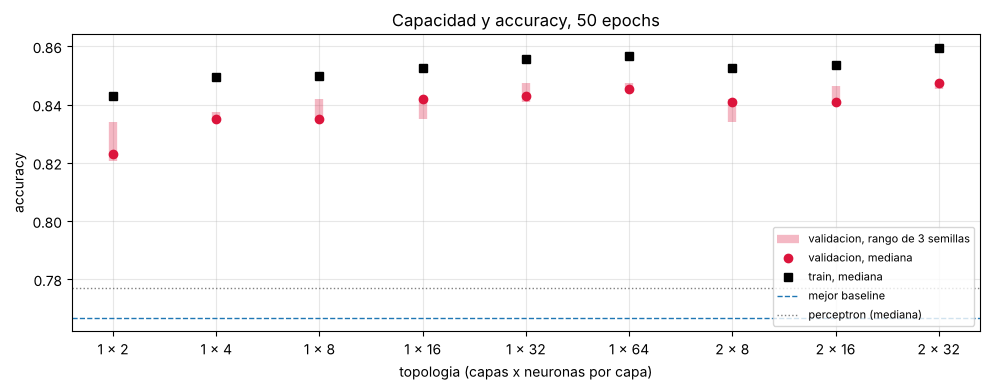

In [19]:
nombres = list(resultados)
med_tr = [np.median(resultados[n]["train"]) for n in nombres]
med_va = [np.median(resultados[n]["val"]) for n in nombres]

plt.figure(figsize=(10, 4))
plt.vlines(range(len(nombres)), [min(resultados[n]["val"]) for n in nombres], [max(resultados[n]["val"]) for n in nombres],
           color="crimson", lw=6, alpha=.3, label="validacion, rango de 3 semillas")
plt.plot(range(len(nombres)), med_va, "o", color="crimson", label="validacion, mediana")
plt.plot(range(len(nombres)), med_tr, "s", color="k", label="train, mediana")
plt.axhline(mejor_baseline, color="tab:blue", ls="--", lw=1, label="mejor baseline")
plt.axhline(np.median(val_perceptron), color="tab:gray", ls=":", lw=1, label="perceptron (mediana)")
plt.xticks(range(len(nombres)), nombres)
plt.xlabel("topologia (capas x neuronas por capa)"); plt.ylabel("accuracy")
plt.title("Capacidad y accuracy, 50 epochs")
plt.legend(fontsize=8, loc="lower right"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

**Cómo elijo.** El criterio es la mediana de la *accuracy* de validación. Pero, como en el Tema 2, clase 2 ("114.45, 113.59 y 111.83 caben en el ruido; lo que se sostiene es la forma"), si varias topologías tienen la mediana dentro del rango de semillas de la mejor, no hay diferencia que se sostenga. Entre ellas me quedo con **la de menos parámetros**: si rinden igual, la más pequeña es la que menos puede memorizar.

In [20]:
mejor_nombre = nombres[int(np.argmax(med_va))]
rango_mejor = (min(resultados[mejor_nombre]["val"]), max(resultados[mejor_nombre]["val"]))

empatadas = [n for n in nombres if np.median(resultados[n]["val"]) >= rango_mejor[0]]
elegida = min(empatadas, key=lambda n: resultados[n]["params"])
capas_elegidas = configuraciones[elegida]

print(f"mejor mediana de validacion: {mejor_nombre} ({max(med_va):.4f}); sus semillas van de {rango_mejor[0]:.4f} a {rango_mejor[1]:.4f}")
print(f"topologias con la mediana dentro de ese rango: {empatadas}")
print(f"\nELEGIDA: {elegida}  ({resultados[elegida]['params']} parametros)")

mejor mediana de validacion: 2 x 32 (0.8475); sus semillas van de 0.8453 a 0.8475
topologias con la mediana dentro de ese rango: ['1 x 64', '2 x 32']

ELEGIDA: 2 x 32  (2145 parametros)


Es la figura de capacidad y error de generalización de la p. 35, con nuestros números, y se lee igual que en el Tema 2, clase 2:

1. **La izquierda es *underfitting*.** Con 2 neuronas, train (0.843) y validación (0.823) son los más bajos del barrido, y validación depende bastante de la semilla.
2. **A partir de 16 neuronas la curva se aplana.** De 1 × 16 (0.842) a 2 × 32 (0.848) hay medio punto: unos 5 días de los 892 de validación. Varias de esas topologías se solapan con el rango de semillas de las demás.
3. **La brecha entre train y validación no crece** con la capacidad: se queda entre 1.0 y 1.3 puntos en todas las redes de 8 o más neuronas. Con 50 *epochs* ninguna llega a memorizar. Al contrario que con los salarios, aquí hay 3564 días de train para como mucho 2177 parámetros.

La regla elige **2 capas ocultas de 32 neuronas** (2145 parámetros). 1 × 64 queda empatada con ella y tiene 2177 parámetros, así que 2 × 32 es la más pequeña de las dos.

La lectura honesta es la del Tema 2: lo que se sostiene es la forma. Con 2–4 neuronas la red se queda corta, y a partir de 16 todas rinden prácticamente igual. No es un problema que pida una red grande: casi toda la mejora está ya en una sola capa oculta pequeña.

## El número de *epochs* (pregunta 7)

Con la topología fijada, la entreno mucho más tiempo, 300 *epochs*, con la validación en cada una, y dibujo las dos curvas de la función de coste. Es la curva de entrenamiento de la p. 39 (Tema 2, clase 1), y se leen juntas:

- si las dos bajan, la red aprende;
- cuando la de validación se estanca y sube mientras la de train sigue bajando, la red memoriza.

Tarda un par de minutos. Elijo la *epoch* con **menor pérdida de validación**, como `mejor_epoch` en el Tema 3, clase 2, parte 2. Uso la pérdida y no la *accuracy* porque es la cantidad que la red optimiza y es más suave: la *accuracy* de validación salta cada vez que un día cruza el 0.5.

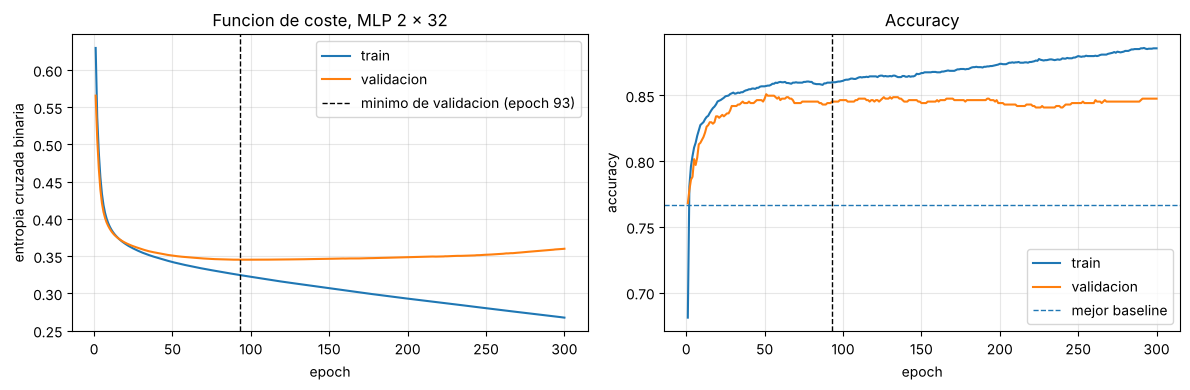

epoch   1   perdida train 0.6295   validacion 0.5655
epoch  10   perdida train 0.3896   validacion 0.3866
epoch  50   perdida train 0.3420   validacion 0.3507
epoch 100   perdida train 0.3221   validacion 0.3453
epoch 200   perdida train 0.2929   validacion 0.3486
epoch 300   perdida train 0.2674   validacion 0.3599

minima perdida de validacion: 0.3451, en la epoch 93


In [21]:
keras.utils.set_random_seed(0)
red_larga = Sequential(
    [Input(shape=(n_entradas,))]
    + [Dense(k, activation="relu") for k in capas_elegidas]
    + [Dense(1, activation="sigmoid")]
)
red_larga.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=eta, momentum=0.0), metrics=["accuracy"])

n_epochs_largo = 300
history = red_larga.fit(X_train, y_train, epochs=n_epochs_largo, batch_size=32,
                        validation_data=(X_val, y_val), verbose=0)

mejor_epoch = int(np.argmin(history.history["val_loss"])) + 1
epochs = np.arange(1, n_epochs_largo + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(epochs, history.history["loss"], label="train")
ax[0].plot(epochs, history.history["val_loss"], label="validacion")
ax[0].axvline(mejor_epoch, color="k", ls="--", lw=1, label=f"minimo de validacion (epoch {mejor_epoch})")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("entropia cruzada binaria"); ax[0].set_title(f"Funcion de coste, MLP {elegida}")
ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(epochs, history.history["accuracy"], label="train")
ax[1].plot(epochs, history.history["val_accuracy"], label="validacion")
ax[1].axhline(mejor_baseline, color="tab:blue", ls="--", lw=1, label="mejor baseline")
ax[1].axvline(mejor_epoch, color="k", ls="--", lw=1)
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("accuracy"); ax[1].set_title("Accuracy")
ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

for e in [1, 10, 50, 100, 200, 300]:
    print(f"epoch {e:3d}   perdida train {history.history['loss'][e - 1]:.4f}   validacion {history.history['val_loss'][e - 1]:.4f}")
print(f"\nminima perdida de validacion: {min(history.history['val_loss']):.4f}, en la epoch {mejor_epoch}")

Las dos curvas bajan juntas durante las primeras decenas de *epochs*: la red aprende. La de validación toca su mínimo, **0.345, en la *epoch* 93**, y desde ahí sube lentamente (0.349 en la 200 y 0.360 en la 300), mientras la de train sigue bajando hasta 0.267. Es el segundo camino al sobreajuste del Tema 2, clase 1: allí el eje era la capacidad, y aquí es el tiempo de entrenamiento. A partir de la *epoch* 100 la red memoriza train.

Me quedo con **93 *epochs***. Parar en ese mínimo es lo que el Tema 2 llama *early stopping* (se desarrolla en el Tema 5). Aquí lo hago a mano: leo la curva una vez y reentreno hasta esa *epoch*.

### ¿Cuánto se mueve el resultado?

La topología elegida, entrenada hasta `mejor_epoch`, con **cinco semillas**. Reporto mediana y rango, y me quedo como modelo final con la semilla de menor pérdida de validación, como hacen `mejores` en el Tema 3, clase 1, y `mlps` en el Tema 4, clase 2.

Son cinco entrenamientos: unos dos minutos.

In [22]:
finales = []
t0 = time.time()
for semilla in range(5):
    keras.utils.set_random_seed(semilla)
    red = Sequential(
        [Input(shape=(n_entradas,))]
        + [Dense(k, activation="relu") for k in capas_elegidas]
        + [Dense(1, activation="sigmoid")]
    )
    red.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=eta, momentum=0.0), metrics=["accuracy"])
    red.fit(X_train, y_train, epochs=mejor_epoch, batch_size=32, verbose=0)
    finales.append({"semilla": semilla, "red": red,
                    "perdida_val": red.evaluate(X_val, y_val, verbose=0)[0],
                    "train": acc_de(red, X_train, y_train), "val": acc_de(red, X_val, y_val)})
    f = finales[-1]
    print(f"semilla {semilla}   perdida val {f['perdida_val']:.4f}   accuracy train {f['train']:.4f}   val {f['val']:.4f}")

acc_val_semillas = [f["val"] for f in finales]
print(f"\nMLP {elegida}, {mejor_epoch} epochs: mediana val {np.median(acc_val_semillas):.4f}   "
      f"min {min(acc_val_semillas):.4f}   max {max(acc_val_semillas):.4f}   ({time.time() - t0:.0f} s)")
print(f"perceptron: mediana val {np.median(val_perceptron):.4f}   min {min(val_perceptron):.4f}   max {max(val_perceptron):.4f}")

final = min(finales, key=lambda f: f["perdida_val"])
modelo_final = final["red"]
print(f"\nmodelo final: semilla {final['semilla']}   train {final['train']:.4f}   validacion {final['val']:.4f}")

semilla 0   perdida val 0.3451   accuracy train 0.8617   val 0.8453


semilla 1   perdida val 0.3482   accuracy train 0.8622   val 0.8453


semilla 2   perdida val 0.3481   accuracy train 0.8662   val 0.8464


semilla 3   perdida val 0.3513   accuracy train 0.8662   val 0.8386


semilla 4   perdida val 0.3495   accuracy train 0.8636   val 0.8442

MLP 2 x 32, 93 epochs: mediana val 0.8453   min 0.8386   max 0.8464   (105 s)
perceptron: mediana val 0.7769   min 0.6704   max 0.8083

modelo final: semilla 0   train 0.8617   validacion 0.8453


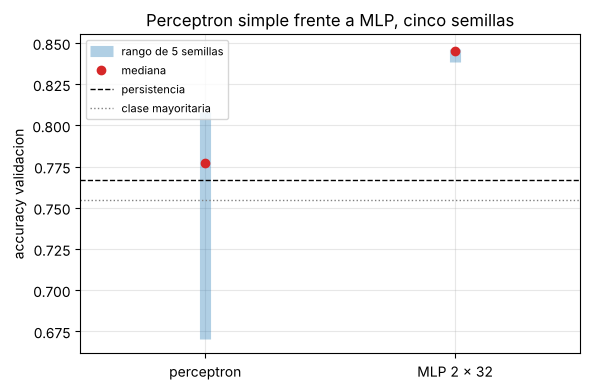

In [23]:
plt.figure(figsize=(6, 4))
grupos = {"perceptron": val_perceptron, f"MLP {elegida}": acc_val_semillas}
plt.vlines(range(2), [min(v) for v in grupos.values()], [max(v) for v in grupos.values()],
           color="tab:blue", lw=8, alpha=.35, label="rango de 5 semillas")
plt.plot(range(2), [np.median(v) for v in grupos.values()], "o", color="tab:red", label="mediana")
plt.axhline(acc_persistencia, color="k", ls="--", lw=1, label="persistencia")
plt.axhline(acc_mayoritaria, color="gray", ls=":", lw=1, label="clase mayoritaria")
plt.xticks(range(2), list(grupos)); plt.xlim(-.5, 1.5)
plt.ylabel("accuracy validacion"); plt.title("Perceptron simple frente a MLP, cinco semillas")
plt.legend(fontsize=8); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

Las cinco semillas del MLP van de 0.839 a 0.846, menos de un punto, con mediana **0.845**. Las del perceptrón van de 0.670 a 0.808. **Las barras no se tocan**: la peor semilla del MLP está 3 puntos por encima de la mejor del perceptrón. Es la conclusión que se sostiene con cualquier semilla, como la de anchura 10 frente a 50 en el Tema 2, clase 1.

El modelo final es la semilla 0 (menor pérdida de validación, 0.345): 0.862 en train y 0.845 en validación.

### Otra gráfica para comprobar que la red es suficientemente buena (pregunta 7)

Con clases desbalanceadas, la *accuracy* esconde **en qué** se equivoca la red: un 84 % puede ser "acierta casi todos los días secos y la mitad de los de lluvia". La **matriz de confusión** (`ConfusionMatrixDisplay`, que importamos en el Tema 1, clase 1) lo separa. Es el equivalente, en clasificación, del gráfico de predicciones frente a valores reales del Tema 2.

A la derecha, el histograma de la probabilidad que da la red, separado por lo que pasó de verdad. Si la red discrimina, los días de lluvia se concentran a la derecha del 0.5 y los secos a la izquierda.

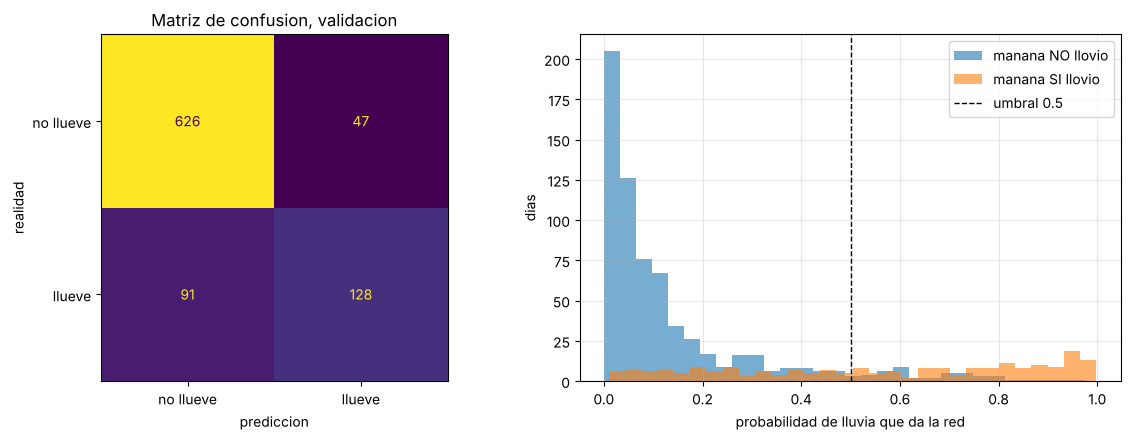

dias de lluvia que la red detecta : 58.4%  (128 de 219)
dias secos que la red acierta     : 93.0%  (626 de 673)
cuando dice 'llueve', acierta el  : 73.1%


In [24]:
prob_val = prob_de(modelo_final, X_val)
pred_val = (prob_val > 0.5).astype(float)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_val, pred_val), display_labels=["no llueve", "llueve"]).plot(ax=ax1, colorbar=False)
ax1.set_xlabel("prediccion"); ax1.set_ylabel("realidad"); ax1.set_title("Matriz de confusion, validacion")

ax2.hist(prob_val[y_val == 0], bins=30, alpha=.6, label="manana NO llovio")
ax2.hist(prob_val[y_val == 1], bins=30, alpha=.6, label="manana SI llovio")
ax2.axvline(0.5, color="k", ls="--", lw=1, label="umbral 0.5")
ax2.set_xlabel("probabilidad de lluvia que da la red"); ax2.set_ylabel("dias"); ax2.legend(); ax2.grid(alpha=.3)
plt.tight_layout(); plt.show()

tn, fp, fn, tp = confusion_matrix(y_val, pred_val).ravel()
print(f"dias de lluvia que la red detecta : {tp / (tp + fn):.1%}  ({tp} de {tp + fn})")
print(f"dias secos que la red acierta     : {tn / (tn + fp):.1%}  ({tn} de {tn + fp})")
print(f"cuando dice 'llueve', acierta el  : {tp / (tp + fp):.1%}")

La *accuracy* de 0.845 esconde dos comportamientos muy distintos:

- **Los días secos los acierta casi todos**: el 93 % (626 de 673).
- **De los días de lluvia solo detecta el 58 %** (128 de 219). Cuando dice "llueve", acierta el 73 % de las veces.

El histograma lo explica. Los días secos se amontonan cerca de 0, pero los de lluvia se reparten por todo el eje, y muchos tienen una probabilidad baja. Con las medidas de hoy, parte de la lluvia de mañana es simplemente impredecible: es el ruido irreducible del Tema 2, el término que no depende del modelo.

Si fallar un día de lluvia costara más que una falsa alarma, se podría bajar el umbral de 0.5, eligiéndolo con validación, igual que movimos el umbral de la neurona gaussiana en el Tema 4, clase 1 ("lo que había que mover era la capa de salida"). No lo hago porque la métrica elegida es la *accuracy*, y para la *accuracy* el umbral natural de una probabilidad es 0.5.

## La columna `Location` (pregunta 9)

**Cómo la he tratado.** Es categórica sin orden y con dos valores: `OneHotEncoder(drop="first")` la deja en una sola columna binaria, `Location_Canberra` (Cairns es la referencia). Además, la estación decide **con qué mediana se imputan** los huecos de cada fila.

**Con qué comparo cada estación.** El rendimiento global mezcla dos climas distintos. En Cairns el día siguiente es de lluvia mucho más a menudo que en Canberra, así que la clase mayoritaria acierta mucho más en Canberra. Una *accuracy* de 0.85 puede batir con holgura al baseline en una estación y quedarse cerca en la otra. Por eso cada estación se compara con **sus propios** baselines, calculados solo con sus días: su clase mayoritaria (la de su train) y su persistencia.

In [25]:
def tabla_por_estacion(X, y_real, loc, hoy, modelo):
    pred = (prob_de(modelo, X) > 0.5).astype(float)
    filas = []
    for estacion in estaciones:
        m = loc == estacion
        mayoritaria_est = int(y_train[loc_train == estacion].mean() >= 0.5)      # la de ESA estacion, en train
        filas.append({"estacion": estacion, "dias": int(m.sum()),
                      "llueve": y_real[m].mean(),
                      "MLP": acc(y_real[m], pred[m]),
                      "mayoritaria": acc(y_real[m], np.full(m.sum(), mayoritaria_est)),
                      "persistencia": acc(y_real[m], hoy[m])})
    tabla = pd.DataFrame(filas).set_index("estacion")
    tabla["MLP - mejor baseline"] = tabla["MLP"] - tabla[["mayoritaria", "persistencia"]].max(axis=1)
    return tabla.round(4)

print("VALIDACION, por estacion")
tabla_por_estacion(X_val, y_val, loc_val, hoy_val, modelo_final)

VALIDACION, por estacion


,dias,llueve,MLP,mayoritaria,persistencia,MLP - mejor baseline
estacion,,,,,,
Cairns,415,0.3157,0.8000,0.6843,0.7398,0.0602
Canberra,477,0.1845,0.8847,0.8155,0.7904,0.0692


Leída sin baselines, la tabla diría que la red funciona mucho mejor en Canberra (0.885) que en Cairns (0.800). Es falso: en Canberra el listón también está más alto.

- **Cairns**: llueve al día siguiente en el 32 % de los casos. La mayoritaria acierta 0.684 y la persistencia 0.740, así que su mejor baseline es la **persistencia**. La red da 0.800: **+6.0 puntos**.
- **Canberra**: llueve en el 18 %. La mayoritaria acierta 0.816 y la persistencia 0.790, así que su mejor baseline es la **clase mayoritaria**. La red da 0.885: **+6.9 puntos**.

Cada estación tiene un baseline ganador distinto. Cairns es más lluviosa y su lluvia viene en rachas (persistencia), y Canberra es más seca (mayoritaria). La red mejora en las dos lo mismo, entre 6 y 7 puntos. Comparar el 0.885 de Canberra con el 0.800 de Cairns sin sus baselines sería comparar dificultades, no modelos.

¿Hace falta la columna `Location`? Lo mido como se mide todo en este curso: la misma topología, las mismas *epochs* y las mismas semillas, **sin esa columna**.

In [26]:
col_loc = nombres_columnas.index("Location_Canberra")
sin_loc = [i for i in range(n_entradas) if i != col_loc]

acc_sin_loc = []
for semilla in range(3):
    keras.utils.set_random_seed(semilla)
    red = Sequential(
        [Input(shape=(len(sin_loc),))]
        + [Dense(k, activation="relu") for k in capas_elegidas]
        + [Dense(1, activation="sigmoid")]
    )
    red.compile(loss="binary_crossentropy", optimizer=SGD(learning_rate=eta, momentum=0.0), metrics=["accuracy"])
    red.fit(X_train[:, sin_loc], y_train, epochs=mejor_epoch, batch_size=32, verbose=0)
    acc_sin_loc.append(acc_de(red, X_val[:, sin_loc], y_val))

print(f"con Location (semillas 0-2): {' '.join(f'{a:.4f}' for a in acc_val_semillas[:3])}   mediana {np.median(acc_val_semillas[:3]):.4f}")
print(f"sin Location (semillas 0-2): {' '.join(f'{a:.4f}' for a in acc_sin_loc)}   mediana {np.median(acc_sin_loc):.4f}")

print("\n¿se distinguen las estaciones sin la columna? medias de train por estacion:")
print(X_train_df.groupby("Location")[["MinTemp", "Temp9am", "Humidity9am", "Pressure9am"]].mean().round(1).to_string())

con Location (semillas 0-2): 0.8453 0.8453 0.8464   mediana 0.8453
sin Location (semillas 0-2): 0.8509 0.8453 0.8408   mediana 0.8453

¿se distinguen las estaciones sin la columna? medias de train por estacion:
          MinTemp  Temp9am  Humidity9am  Pressure9am
Location                                            
Cairns       21.1     25.8         69.7       1014.3
Canberra      6.9     12.8         73.3       1019.0


Con y sin la columna, la mediana es la misma, 0.845, y las semillas se mueven dentro del mismo rango. La red no necesita que le digan la estación, porque la reconstruye a partir del resto de variables. La temperatura mínima media es de 21 °C en Cairns y de 7 °C en Canberra, y con eso basta para distinguirlas.

Es la idea de **variable proxy** del Tema 2, clase 1 (el sexo reconstruido a partir del puesto y los estudios): quitar una columna no quita su información si otras la contienen. Mantengo `Location` porque no cuesta nada, hace explícita una diferencia que existe y ya se usa en la imputación.

## Las derivadas para montarlo en `numpy` (pregunta 8)

Para entrenar con *backpropagation* hace falta la derivada de cada activación. Es el factor $h'$ de la relación de recurrencia: "el gradiente que atraviesa esa capa lleva un factor $h'$" (Tema 2, clase 2). Esta red usa dos activaciones distintas.

**ReLU** (capas ocultas), $\;h(z) = \max(0, z)$:
$$h'(z) = \begin{cases} 1 & z > 0 \\ 0 & z < 0 \end{cases}$$
En $z = 0$ no es derivable; en la práctica se toma $h'(0) = 0$. Esta derivada explica que una ReLU pueda "morir": si $z < 0$ para todas las muestras, el gradiente es exactamente cero y la neurona no vuelve a actualizarse (Tema 2, clase 2).

**Sigmoide** (salida), $\;\sigma(z) = \dfrac{1}{1 + e^{-z}} = (1 + e^{-z})^{-1}$. Por la regla de la cadena:
$$\sigma'(z) = -(1 + e^{-z})^{-2}\cdot(-e^{-z}) = \frac{e^{-z}}{(1 + e^{-z})^2} = \underbrace{\frac{1}{1 + e^{-z}}}_{\sigma(z)}\cdot\underbrace{\frac{e^{-z}}{1 + e^{-z}}}_{1 - \sigma(z)} = \sigma(z)\,\big(1 - \sigma(z)\big)$$
porque $\dfrac{e^{-z}}{1+e^{-z}} = \dfrac{(1 + e^{-z}) - 1}{1+e^{-z}} = 1 - \sigma(z)$. Se calcula con la propia salida $a = \sigma(z)$, sin volver a evaluar exponenciales, y vale como mucho $1/4$ (en $z = 0$).

**Con la entropía cruzada binaria**, $\;\mathcal{L} = -\big[y\ln a + (1-y)\ln(1-a)\big]$ con $a = \sigma(z)$:
$$\frac{\partial \mathcal{L}}{\partial a} = -\frac{y}{a} + \frac{1-y}{1-a} = \frac{a - y}{a(1-a)}, \qquad
\frac{\partial \mathcal{L}}{\partial z} = \frac{\partial \mathcal{L}}{\partial a}\,\sigma'(z) = \frac{a-y}{a(1-a)}\cdot a(1-a) = a - y$$
El $\sigma'$ se cancela: el error que entra en la red por la salida es simplemente $a - y$, y desde ahí se propaga hacia atrás multiplicando por los pesos y por el $h'(z) \in \{0, 1\}$ de cada ReLU. Es la misma forma que la regla del perceptrón del Tema 1, $(y - \hat{y})$, con el signo cambiado porque en el descenso de gradiente se resta.

Para montarla en `numpy` hacen falta, por tanto, **dos** derivadas de activaciones: $h'$ de la ReLU y $\sigma'$ de la sigmoide (o, directamente, el atajo $a - y$ si la pérdida es la entropía cruzada).

Comprobación numérica: las derivadas analíticas frente a diferencias finitas centradas, $\dfrac{f(z+\varepsilon) - f(z-\varepsilon)}{2\varepsilon}$.

In [27]:
def relu(z):            return np.maximum(0, z)
def relu_deriv(z):      return (z > 0).astype(float)
def sigmoide(z):        return 1 / (1 + np.exp(-z))
def sigmoide_deriv(z):  return sigmoide(z) * (1 - sigmoide(z))

z = np.array([-3.0, -0.5, 0.3, 2.0])
eps = 1e-6
for nombre, f, df in [("ReLU", relu, relu_deriv), ("sigmoide", sigmoide, sigmoide_deriv)]:
    numerica = (f(z + eps) - f(z - eps)) / (2 * eps)
    print(f"{nombre:9s} z = {z}   analitica {df(z).round(6)}   numerica {numerica.round(6)}")

for y_ej in [0.0, 1.0]:
    perdida = lambda zz: -(y_ej * np.log(sigmoide(zz)) + (1 - y_ej) * np.log(1 - sigmoide(zz)))
    numerica = (perdida(0.3 + eps) - perdida(0.3 - eps)) / (2 * eps)
    print(f"y = {y_ej:.0f}, z = 0.3:  dL/dz numerica {numerica:.6f}   a - y = {sigmoide(0.3) - y_ej:.6f}")

ReLU      z = [-3.  -0.5  0.3  2. ]   analitica [0. 0. 1. 1.]   numerica [0. 0. 1. 1.]
sigmoide  z = [-3.  -0.5  0.3  2. ]   analitica [0.045177 0.235004 0.244458 0.104994]   numerica [0.045177 0.235004 0.244458 0.104994]
y = 0, z = 0.3:  dL/dz numerica 0.574443   a - y = 0.574443
y = 1, z = 0.3:  dL/dz numerica -0.425557   a - y = -0.425557


## El conjunto de test

Todo el notebook ha decidido mirando validación: $\eta$, la topología, las *epochs* y la semilla. Ahora el modelo final se mide en test **una sola vez**, junto a los baselines, en global y por estación. Si la selección no ha contaminado nada, el test tiene que salir en la misma zona que la validación (Tema 2, clase 2).

In [28]:
print(f"MLP {elegida}, {mejor_epoch} epochs, eta = {eta}, B = 32, semilla {final['semilla']}\n")
print(f"accuracy TRAIN      : {acc_de(modelo_final, X_train, y_train):.4f}")
print(f"accuracy VALIDACION : {acc_de(modelo_final, X_val, y_val):.4f}")
print(f"accuracy TEST       : {acc_de(modelo_final, X_test, y_test):.4f}   <- la unica vez\n")

perceptron_final = Perceptron(random_state=int(np.argmax(val_perceptron))).fit(X_train, y_train)
print("referencias en test:")
print(f"  clase mayoritaria : {acc(y_test, np.full_like(y_test, mayoritaria)):.4f}")
print(f"  persistencia      : {acc(y_test, hoy_test):.4f}")
print(f"  perceptron simple : {acc(y_test, perceptron_final.predict(X_test)):.4f}   (la semilla con mejor validacion)\n")

print("TEST, por estacion")
print(tabla_por_estacion(X_test, y_test, loc_test, hoy_test, modelo_final).to_string())

MLP 2 x 32, 93 epochs, eta = 0.01, B = 32, semilla 0

accuracy TRAIN      : 0.8617
accuracy VALIDACION : 0.8453
accuracy TEST       : 0.8398   <- la unica vez

referencias en test:
  clase mayoritaria : 0.7550
  persistencia      : 0.7623
  perceptron simple : 0.8089   (la semilla con mejor validacion)

TEST, por estacion
          dias  llueve     MLP  mayoritaria  persistencia  MLP - mejor baseline
estacion                                                                       
Cairns     890  0.3157  0.8112       0.6843        0.7551                0.0562
Canberra  1020  0.1833  0.8647       0.8167        0.7686                0.0480


**0.840 en test, frente a 0.845 en validación y 0.862 en train.** El test sale en la misma zona que la validación, que es lo que tiene que pasar si la selección no ha contaminado nada. El medio punto de diferencia equivale a unos 10 días de 1910.

Contra las referencias, en test: **+7.8 puntos** sobre la persistencia (0.762), +8.5 sobre la clase mayoritaria (0.755) y +3.1 sobre el mejor perceptrón (0.809). Por estación, la red bate en las dos a su mejor baseline: Cairns 0.811 frente a 0.755 de la persistencia (+5.6) y Canberra 0.865 frente a 0.817 de la mayoritaria (+4.8).

## Respuestas

Los números son los de este notebook. Si al ejecutarlo en otro entorno cambia alguna cifra decimal, las conclusiones son las mismas.

**1. ¿Qué transformaciones has hecho sobre los datos? ¿Has eliminado alguna columna? ¿Cuál y por qué?**

- He eliminado **la columna `Date`**. Es el identificador de la fila, no una medida del tiempo (como `Name` en el Titanic). Con una partición aleatoria, la red podría aprender "qué tiempo hizo esa semana" en lugar de relaciones que generalicen, y la estación del año ya la recogen las temperaturas. Solo la he usado aparte para comprobar la partición.
- He eliminado **40 filas** (0.6 %), las de los días en que no se midió la lluvia (`Rainfall` y `RainToday` vacíos a la vez). No hay duplicados que quitar.
- `RainToday` y `RainTomorrow`: de `Yes`/`No` a 1/0 (`map`, Tema 1).
- Partición en train/validación/test (56 % / 14 % / 30 %: primero el 30 % de test y luego el 20 % del resto para validación), estratificada por estación y objetivo, **antes** de cualquier transformación.
- Imputación de las numéricas con la **mediana de train de cada estación**: los ausentes se concentran en Canberra, en `Evaporation`, `Sunshine` y `Cloud`.
- `WindGustDir`: los ausentes como categoría `"desconocida"` y `OneHotEncoder(drop="first")`, porque no tiene orden. `Location`: una sola columna binaria con el mismo *encoder*.
- `StandardScaler` sobre las 14 numéricas, ajustado con train y aplicado a los tres conjuntos. Las binarias se quedan en 0/1.
- La imputación, el *encoder* y el escalador se **ajustan solo con train**. Resultado: 32 entradas.

**2. ¿Qué funciones de activación has elegido para las capas ocultas y para la capa de salida?**

**ReLU** en las capas ocultas: es la activación oculta de todas las redes del curso, es barata, y su derivada vale 1 en la parte activa, así que no atenúa el gradiente al propagarlo hacia atrás. **Sigmoide** en la neurona de salida: es una clasificación binaria, y la sigmoide da un número en $(0, 1)$ que se interpreta como $P(\text{llueve mañana})$ y se umbraliza en 0.5 (tabla tarea → activación de salida → coste, p. 15). Una salida lineal no da una probabilidad, y una ReLU en la salida puede morir (Tema 2, clase 2).

**3. ¿Qué función de coste has utilizado? ¿Qué métrica de evaluación has escogido?**

Coste: **entropía cruzada binaria** (`binary_crossentropy`), la que acompaña a la salida sigmoide (Tema 4, clase 1). Con la sigmoide, su gradiente respecto a $z$ es simplemente $a - y$ (pregunta 8). Con el MSE aparecería un factor $\sigma'(z)$ que tiende a 0 cuando la sigmoide se satura, justo cuando la red se equivoca con mucha confianza.

Métrica: **accuracy**, como en el Tema 1, siempre comparada con los baselines (0.755 la mayoritaria y 0.767 la persistencia): con un 25 % de días de lluvia, una *accuracy* suelta no dice nada. La complemento con la **matriz de confusión**, que muestra que la red acierta el 93 % de los días secos y el 58 % de los de lluvia.

**4. Compara el resultado de un perceptrón simple frente a una red neuronal.**

En validación, con cinco semillas: el perceptrón tiene mediana **0.777** y rango de 0.670 a 0.808, 14 puntos según el orden de las muestras, y con una semilla queda por debajo de la clase mayoritaria. El MLP elegido tiene mediana **0.845** y rango de 0.839 a 0.846. Las barras no se tocan, así que la diferencia es real. En test: perceptrón 0.809 y MLP 0.840.

El perceptrón solo traza un hiperplano y su regla solo corrige cuando falla, así que con clases que se solapan no converge. El MLP añade una capa oculta no lineal y minimiza la entropía cruzada con descenso de gradiente.

**5. ¿Cuántas capas y cuántas neuronas por capa tiene? ¿Cómo has llegado a ella?**

**2 capas ocultas de 32 neuronas ReLU** y una salida sigmoide: 32 → 32 → 32 → 1, 2145 parámetros. He barrido 1 capa con 2, 4, 8, 16, 32 y 64 neuronas y 2 capas con 8, 16 y 32, todas con el mismo presupuesto (50 *epochs*, $\eta = 0.01$, $B = 32$) y **tres semillas por punto**. He elegido por la mediana de la *accuracy* de validación y, entre las topologías empatadas dentro del rango de semillas de la mejor (1 × 64 y 2 × 32), la de menos parámetros.

La curva muestra *underfitting* con 2–4 neuronas y un aplanamiento a partir de 16: de 1 × 16 a 2 × 32 hay medio punto. Lo que se sostiene es que una red pequeña de una o dos capas basta y que más capacidad no aporta.

**6. ¿Cuál es el error o la accuracy que obtienes sobre los datos de entrenamiento, de validación y de test? ¿Óptima, *overfitting* o *underfitting*?**

*Accuracy*: **train 0.862, validación 0.845, test 0.840**.

- **No hay *overfitting* apreciable.** La brecha train–validación es de 1.7 puntos y el test confirma la validación. Lo he evitado parando en la *epoch* 93: entrenando hasta la 300, la pérdida de validación sube de 0.345 a 0.360 mientras la de train sigue bajando, y eso sí sería sobreajuste.
- **Tampoco *underfitting* por falta de capacidad.** Las redes más grandes del barrido no mejoran en validación, y la *accuracy* de train apenas sube con la capacidad (de 0.85 a 0.86).
- **El techo del 84–86 % viene de los datos**, no de la red. Con las medidas de hoy, parte de la lluvia de mañana es impredecible: el 42 % de los días de lluvia de validación quedan por debajo de 0.5 de probabilidad. Es el ruido irreducible.

Dentro de lo que se puede hacer con estas variables y SGD, la configuración está cerca de lo óptimo: las diferencias con las alternativas razonables caben en el ruido entre semillas.

**7. ¿Cuántas *epochs* y cómo las has elegido? Gráfica de la función de coste. ¿Qué otra gráfica podrías utilizar?**

**93 *epochs***. He entrenado la topología elegida 300 *epochs* con la validación en cada una (gráfica en la sección *El número de epochs*). Las dos curvas bajan juntas hasta la *epoch* 93, donde la pérdida de validación toca su mínimo (0.345). Desde ahí sube mientras la de train sigue bajando, así que he tomado ese mínimo (*early stopping* a mano, como `mejor_epoch` en el Tema 3, clase 2) y he reentrenado hasta él con cinco semillas.

Otra gráfica: la **matriz de confusión** de validación (`ConfusionMatrixDisplay`, Tema 1), que separa los aciertos por clase: 93 % de los días secos y 58 % de los de lluvia. También el **histograma de la probabilidad predicha** separado por la clase real, que muestra si la red separa las dos clases y dónde se solapan.

**8. ¿Qué derivadas de funciones de activación necesitas? Derívalas.**

Dos, desarrolladas en la sección de las derivadas y comprobadas numéricamente allí mismo:

- **ReLU**: $h(z) = \max(0, z)$, $\;h'(z) = 1$ si $z > 0$ y $0$ si $z < 0$ (en $z = 0$ se toma 0).
- **Sigmoide**: $\sigma(z) = (1 + e^{-z})^{-1}$, $\;\sigma'(z) = \dfrac{e^{-z}}{(1+e^{-z})^2} = \sigma(z)\,(1 - \sigma(z))$.

Con la entropía cruzada binaria, $\dfrac{\partial \mathcal{L}}{\partial z_{\text{salida}}} = \dfrac{a-y}{a(1-a)}\cdot a(1-a) = a - y$. Ese error se propaga hacia atrás multiplicando por los pesos y por $h'(z)$ en cada capa ReLU.

**9. ¿Cómo has tratado la columna `Location`? ¿Cómo rinde tu red en cada estación, y con qué comparas cada resultado?**

`Location` es categórica sin orden con dos valores: `OneHotEncoder(drop="first")` la deja en una columna binaria, `Location_Canberra`. Además, la imputación de ausentes se hace con las medianas de train **de cada estación**, y la partición está estratificada por estación y objetivo.

Cada estación se compara con **sus propios baselines**, calculados con sus días: su clase mayoritaria y su persistencia. En test:

| | días | llueve al día siguiente | MLP | mayoritaria | persistencia | MLP − mejor baseline |
|---|---|---|---|---|---|---|
| Cairns | 890 | 31.6 % | **0.811** | 0.684 | 0.755 | +5.6 |
| Canberra | 1020 | 18.3 % | **0.865** | 0.817 | 0.769 | +4.8 |

Sin baselines parecería que la red funciona mucho mejor en Canberra, pero allí el listón es más alto. En Cairns el mejor baseline es la persistencia (la lluvia viene en rachas) y en Canberra la clase mayoritaria (es más seca), y la red mejora a los dos en una magnitud parecida. Quitando la columna, la red rinde igual (mediana 0.845 en validación): reconstruye la estación a partir de las temperaturas (mínima media de 21 °C en Cairns frente a 7 °C en Canberra). Es una variable proxy, como en el Tema 2.